# IWTT exploratory analysis

Getting to know the EPA Industrial Wastewater Treatment Technology (IWTT) database before building more of the pollutant field app.

**Run it in VS Code:** open this file, pick your conda `base` kernel in the top right, and Run All. It looks for the CSVs in `data/iwtt/` next to this notebook.
**Run it in Colab:** upload the 9 IWTT CSVs to the Files panel (left sidebar) and Run All.

The last section exports `iwtt_tidy.csv`, one row per measurement per treatment unit, which is the table the app is built from.

In [1]:
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# find the data whether you're in the repo or in Colab
for cand in [Path("data/iwtt"), Path("../data/iwtt"), Path(".")]:
    if (cand / "PARAMETER.csv").exists():
        DATA = cand; break
else:
    raise FileNotFoundError("Put the IWTT CSVs in data/iwtt/ (or upload them to Colab)")

R = lambda f: pd.read_csv(DATA / f, encoding="latin1")   # files contain µ, so not utf-8
ref, sys_, units, params = R("REFERENCE_INFO.csv"), R("TREATMENT_SYSTEM.csv"), R("TREATMENT_UNITS.csv"), R("PARAMETER.csv")
k_tt, k_par = R("KEY_TREATMENT_TECH_CODES.csv"), R("KEY_PARAMETER_CODE.csv")
k_stat = R("KEY_PERFORMSTAT.csv")

pd.DataFrame({"rows": [len(x) for x in (ref, sys_, units, params, k_tt, k_par)]},
             index=["REFERENCE_INFO", "TREATMENT_SYSTEM", "TREATMENT_UNITS", "PARAMETER", "KEY_TREATMENT_TECH_CODES", "KEY_PARAMETER_CODE"])

,rows
REFERENCE_INFO,50
TREATMENT_SYSTEM,325
TREATMENT_UNITS,965
PARAMETER,1669
KEY_TREATMENT_TECH_CODES,67
KEY_PARAMETER_CODE,2115


## 1. How the tables connect

```
REFERENCE_INFO        one row per paper or report             key: REF_ID
  └─ TREATMENT_SYSTEM one row per system studied in a paper   key: REF_ID + SYSTEM_NAME (e.g. "41T1")
       ├─ TREATMENT_UNITS   ordered units in the train        TT_CODE → KEY_TREATMENT_TECH_CODES
       └─ PARAMETER         pollutant performance records     PARAMID → KEY_PARAMETER_CODE
```

The unit of analysis that matters most is a **PARAMETER row**: one pollutant measured before and after one whole treatment system.

In [2]:
checks = {
    "papers with full reference info": ref.REF_ID.nunique(),
    "papers referenced by systems": sys_.REF_ID.nunique(),
    "systems": sys_.SYSTEM_NAME.nunique(),
    "systems with unit lists": units.SYSTEM_NAME.nunique(),
    "systems with performance data": params.SYSTEM_NAME.nunique(),
    "performance records": len(params),
    "performance records whose paper has no reference row": (~params.REF_ID.isin(ref.REF_ID)).sum(),
}
pd.Series(checks)

papers with full reference info                           50
papers referenced by systems                             208
systems                                                  325
systems with unit lists                                  332
systems with performance data                            253
performance records                                     1669
performance records whose paper has no reference row    1567
dtype: int64

**Note:** `REFERENCE_INFO` only covers a subset of the papers. Treat paper-level fields (abstract, country, motivation, year) as a sample, and lean on `TREATMENT_SYSTEM` and `PARAMETER` for anything that should cover the whole database.

## 2. Data quality

In [3]:
# HASPERFDATA is stored four different ways
print(sys_.HASPERFDATA.value_counts(dropna=False), "\n")
sys_["has_perf"] = sys_.HASPERFDATA.astype(str).str.upper().isin(["TRUE", "1"])

# removal: UPDATEREMOVAL is the cleaned value (reported, else calculated)
params["removal"] = pd.to_numeric(params.UPDATEREMOVAL, errors="coerce")
print("records with a removal %:", params.removal.notna().sum(), "of", len(params))
print("records with influent and effluent concentrations:",
      (params.INFLUENTCONCENTRATION.notna() & params.EFFLUENTCONCENTRATION.notna()).sum())

HASPERFDATA
True     178
1         78
False     61
TRUE       4
0          4
Name: count, dtype: int64 

records with a removal %: 1117 of 1669
records with influent and effluent concentrations: 1403


In [4]:
# units are mixed (mg/L, ng/L, µg/L, ppm, NTU...), so compare pollutants by % removal, not concentration
params.INFLUENTUNITS.value_counts().head(12)

INFLUENTUNITS
mg/L             879
ng/L             410
µg/L             118
ppm               36
ppb               14
g/L               12
NTU               12
µS/cm              6
mS/cm              6
mg O2/L            4
mg/L as CaCO3      4
mV                 3
Name: count, dtype: int64

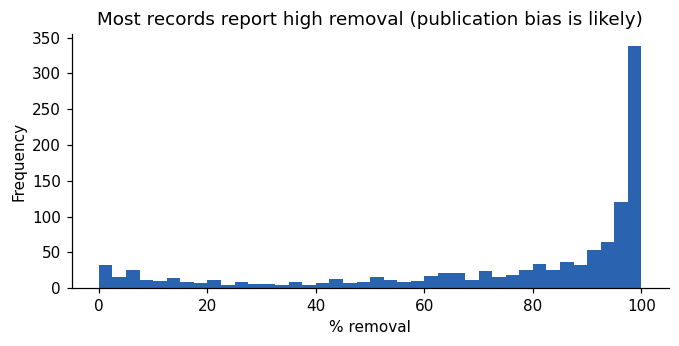

PERFORMSTAT
Average        789
Unspecified    455
Individual     335
Maximum         44
Median          25
Minimum          9
Name: count, dtype: int64

In [5]:
fig, ax = plt.subplots(figsize=(7, 3))
params.removal.dropna().plot.hist(bins=40, ax=ax, color="#2a64b0")
ax.set_xlabel("% removal"); ax.set_title("Most records report high removal (publication bias is likely)")
plt.show()

params.merge(k_stat, on="PERFORMSTATID").PERFORMSTAT.value_counts()

## 3. Pollutant taxonomy and the tidy table

Same rules as `scripts/build_data.py`. If you change one, change both (or ask Claude Code to move the taxonomy into a shared `taxonomy.py`).

In [6]:
HEAVY_METALS = {"Selenium","Chromium","Copper","Zinc","Iron","Nickel","Lead","Cadmium","Mercury","Arsenic","Aluminum","Manganese","Barium","Silver","Strontium","Tin","Vanadium","Beryllium","Cobalt","Antimony","Thallium","Molybdenum","Titanium","Cesium"}
INORGANIC = {"Chloride","Calcium","Sulfate","Sodium","Magnesium","Potassium","Fluoride","Bromide","Boron","Silicon","Cyanide","Cyanate","Thiocyanate","Sulfide","Hydrogen sulfide","Perchlorate","Bicarbonate","Carbonate","Hardness","Alkalinity","Chlorine","Halogens","Nitrogen oxides"}
PHARMA = {"Ciprofloxacin","Ampicillin","Azithromycin","Morphine","Metronidazol","Diclofenac","Chlortetracycline","Bisoprolol","Carbamazepine","Active Pharmaceutical Ingredients (APIs)","Estrogenicity"}
SUSPENDED = {"Solids, suspended","Turbidity","Solids, total","Color"}
DISSOLVED = {"Solids, dissolved","Conductivity"}
OILS = {"Oil and grease","Fats, oils, and grease"}
CONDITION = {"Dissolved oxygen","ORP","pH range excursion","Carbon dioxide"}
ORGANIC_LOAD = {"Chemical oxygen demand (COD)","Biochemical oxygen demand (BOD)","Carbon","Oxygen Demand","Organic compounds"}
NUTRIENTS = {"Ammonia","Phosphorus","Nitrogen, Total Kjeldahl (TKN)","Nitrate","Nitrogen","Nitrite","Phosphate","Ammonium"}

def classify(t):
    if "PFAS" in t: return "Chemical", "PFAS"
    for s, fam, sub in [(HEAVY_METALS,"Chemical","Heavy metals"),(INORGANIC,"Chemical","Inorganic ions and salts"),
                        (PHARMA,"Chemical","Pharmaceuticals"),(SUSPENDED,"Physical","Suspended solids and turbidity"),
                        (DISSOLVED,"Physical","Dissolved solids and salinity"),(OILS,"Physical","Oils and grease"),
                        (CONDITION,"Physical","Water condition"),(ORGANIC_LOAD,"Biological","Sewage and organic load"),
                        (NUTRIENTS,"Biological","Nutrients")]:
        if t in s: return fam, sub
    return "Chemical", "Hydrocarbons and organics"

params = params.merge(k_par[["PARAMID", "POLLUTANT_SEARCH_TERM", "CATEGORY"]], on="PARAMID", how="left")
params["pollutant"] = params.POLLUTANT_SEARCH_TERM.fillna(params.PARAMETER).str.replace(r"\s+", " ", regex=True).str.strip()
params[["family", "sub"]] = params.pollutant.apply(lambda t: pd.Series(classify(t)))

k_tt["tt_cat"] = k_tt.TT_CATEGORY.replace({"Physical, NEC": "Physical"})
records = params.merge(sys_[["REF_ID", "SYSTEM_NAME", "INDUSTRY", "SCALE"]], on=["REF_ID", "SYSTEM_NAME"], how="left")

# tidy: one row per performance record per unit in that system's train
tidy = (records.merge(units, on=["REF_ID", "SYSTEM_NAME"])
               .merge(k_tt[["TT_CODE", "TT_NAME", "tt_cat"]], on="TT_CODE"))
print(len(records), "records ->", len(tidy), "record x unit rows")
records[["family", "sub"]].value_counts().rename("records").to_frame()

1669 records -> 5162 record x unit rows


records
family     sub                                    
Chemical   PFAS                                410
           Heavy metals                        301
Biological Nutrients                           243
           Sewage and organic load             202
Chemical   Inorganic ions and salts            195
Physical   Suspended solids and turbidity      125
Chemical   Hydrocarbons and organics            71
Physical   Dissolved solids and salinity        51
           Oils and grease                      46
           Water condition                      13
Chemical   Pharmaceuticals                      12

## 4. What gets measured (research attention)

In [7]:
att = (records.groupby(["family", "sub"])
              .agg(records=("pollutant", "size"), pollutants=("pollutant", "nunique"),
                   systems=("SYSTEM_NAME", "nunique"), papers=("REF_ID", "nunique"))
              .sort_values("records", ascending=False))
att

records  pollutants  systems  papers
family     sub                                                                 
Chemical   PFAS                                410          27       34       5
           Heavy metals                        301          24       76      60
Biological Nutrients                           243           8      100      74
           Sewage and organic load             202           5      127      93
Chemical   Inorganic ions and salts            195          23       63      52
Physical   Suspended solids and turbidity      125           4       85      64
Chemical   Hydrocarbons and organics            71          33       32      25
Physical   Dissolved solids and salinity        51           2       41      33
           Oils and grease                      46           2       39      30
           Water condition                      13           4       11       8
Chemical   Pharmaceuticals                      12          11        4       3

In [8]:
# a lot of records can come from very few papers: check concentration of evidence
top = records.groupby("pollutant").agg(records=("REF_ID", "size"), papers=("REF_ID", "nunique"),
                                       systems=("SYSTEM_NAME", "nunique"), family=("family", "first"))
top.sort_values("records", ascending=False).head(20)

,records,papers,systems,family
pollutant,,,,
Chemical oxygen demand (COD),121,83,115,Biological
"Solids, suspended",92,61,80,Physical
Ammonia,86,56,79,Biological
Biochemical oxygen demand (BOD),58,43,57,Biological
Phosphorus,42,31,40,Biological
Selenium,37,23,27,Chemical
"Solids, dissolved",37,29,37,Physical
Perfluorononanoic acid (PFAS),33,4,33,Chemical
Perfluorodecanoic acid (PFAS),33,4,33,Chemical


Watch the `papers` column. PFAS look heavily studied by record count, but most of those records come from a handful of papers that each measured dozens of PFAS compounds. Size dots by **papers or systems** in the app if you want marks to reflect independent evidence.

## 5. What treats what

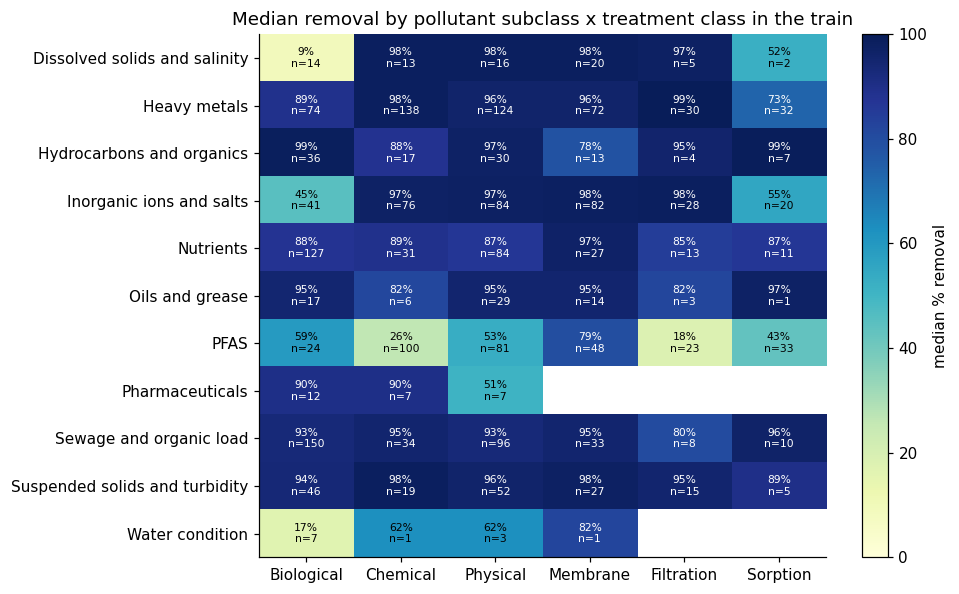

In [9]:
# removal is reported per system, so attribute it to the system's treatment classes (one vote per class per record)
sys_cats = tidy.drop_duplicates(["REF_ID", "SYSTEM_NAME", "PARAMID", "tt_cat"])
pivot_med = sys_cats.pivot_table(index="sub", columns="tt_cat", values="removal", aggfunc="median")
pivot_n = sys_cats.pivot_table(index="sub", columns="tt_cat", values="removal", aggfunc="count")
order = ["Biological", "Chemical", "Physical", "Membrane", "Filtration", "Sorption"]
pivot_med, pivot_n = pivot_med.reindex(columns=order), pivot_n.reindex(columns=order)

fig, ax = plt.subplots(figsize=(9, 5.5))
im = ax.imshow(pivot_med.values, cmap="YlGnBu", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(order)), order); ax.set_yticks(range(len(pivot_med)), pivot_med.index)
for i in range(pivot_med.shape[0]):
    for j in range(pivot_med.shape[1]):
        m, n = pivot_med.iat[i, j], pivot_n.iat[i, j]
        ax.text(j, i, "" if np.isnan(m) else f"{m:.0f}%\nn={int(n)}", ha="center", va="center", fontsize=7,
                color="white" if (not np.isnan(m) and m > 70) else "black")
fig.colorbar(im, label="median % removal"); ax.set_title("Median removal by pollutant subclass x treatment class in the train")
plt.tight_layout(); plt.show()

Blank cells are combinations nobody has published on. Low `n` cells are guesses. This heatmap is the analytical version of the app's Matrix view.

In [10]:
# hard to treat: the best technology for this pollutant still has a low median
best = (tidy.dropna(subset=["removal"])
            .groupby(["pollutant", "TT_NAME"]).removal.median()
            .groupby("pollutant").agg(best_removal="max", best_tech="idxmax"))
best["best_tech"] = best.best_tech.str[1]
best = best.join(records.groupby("pollutant")[["family", "sub"]].first())
hard = best[best.best_removal < 70].sort_values("best_removal")
print(len(hard), "pollutants never reach 70% median removal with any single technology's trains")
hard

17 pollutants never reach 70% median removal with any single technology's trains


,best_removal,best_tech,family,sub
pollutant,,,,
Trichloroacetic acid,3.703704,Biologically Active Filters,Chemical,Hydrocarbons and organics
Isopropanol,8.330000,Forward Osmosis,Chemical,Hydrocarbons and organics
Perfluorobutanoic Acid (PFAS),12.083333,Chemical Disinfection,Chemical,PFAS
Methyl ethyl ketone,13.520000,Forward Osmosis,Chemical,Hydrocarbons and organics
Acetone,14.700000,Forward Osmosis,Chemical,Hydrocarbons and organics
Azithromycin,21.000000,Clarification,Chemical,Pharmaceuticals
Perfluorodecane Sulfonate (PFAS),36.363636,Aerobic Biological Treatment,Chemical,PFAS
Chlortetracycline,36.666667,Anaerobic Suspended Growth,Chemical,Pharmaceuticals
Total PFAAs (PFAS),43.000000,Granular Activated Carbon Unit,Chemical,PFAS


## 6. Treatment trains

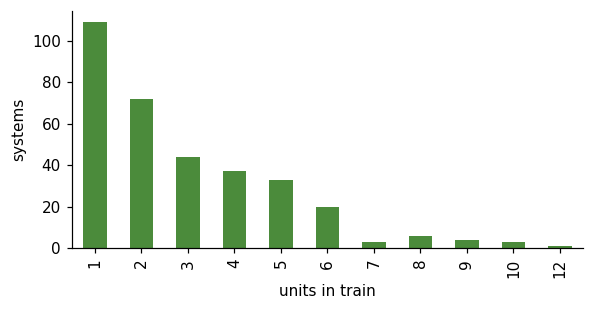

Chemical Precipitation > Clarification                             22
Micro- and Ultra-Membrane Filtration > Reverse Osmosis             16
Mechanical Pre-Treatment > Flow Equalization                       14
Aerobic Suspended Growth > Clarification                           11
Flow Equalization > Chemical Precipitation                         10
Clarification > Granular-Media Filtration                           9
Chemical Precipitation > Micro- and Ultra-Membrane Filtration       9
Chemical Precipitation > Dissolved Air Flotation                    8
Anaerobic Biological Treatment > Aerobic Biological Treatment       8
Evaporation > Crystallization                                       8
Aerobic Suspended Growth > Aerobic Suspended Growth                 7
Mechanical Pre-Treatment > Micro- and Ultra-Membrane Filtration     7
Clarification > Chemical Precipitation                              7
Oil/Water Separation > Flow Equalization                            7
Dissolved Air Flotat

In [11]:
trains = units.sort_values("TT_CODE_ORDER").groupby(["REF_ID", "SYSTEM_NAME"]).TT_CODE.apply(list)
fig, ax = plt.subplots(figsize=(6, 2.8))
trains.str.len().value_counts().sort_index().plot.bar(ax=ax, color="#4b8b3b")
ax.set_xlabel("units in train"); ax.set_ylabel("systems"); plt.show()

name = dict(zip(k_tt.TT_CODE, k_tt.TT_NAME))
pairs = trains.apply(lambda t: list(zip(t, t[1:]))).explode().dropna()
pd.Series([f"{name[a]} > {name[b]}" for a, b in pairs]).value_counts().head(15).rename("systems")

## 7. Who generates which pollutants

In [12]:
ind = records.groupby(["INDUSTRY", "sub"]).size().unstack(fill_value=0)
ind = ind.loc[ind.sum(axis=1).sort_values(ascending=False).index[:12]]
ind

sub,Dissolved solids and salinity,Heavy metals,Hydrocarbons and organics,Inorganic ions and salts,Nutrients,Oils and grease,PFAS,Pharmaceuticals,Sewage and organic load,Suspended solids and turbidity,Water condition
INDUSTRY,,,,,,,,,,,
Drinking water treatment,0,0,0,0,0,0,386,0,0,0,0
Steam electric power generating,8,90,4,50,21,0,0,0,9,6,0
Petroleum refining,4,22,7,13,50,6,0,0,37,26,0
Metal finishing,3,58,5,17,15,12,0,0,16,10,0
Oil and gas extraction,4,23,34,27,11,4,0,0,14,4,2
Meat and poultry products,0,0,3,1,23,6,0,0,19,18,0
Transportation equipment cleaning,0,20,4,1,1,9,0,0,10,9,0
Leather tanning and finishing,8,0,0,4,15,0,0,0,7,4,4
Canned and preserved fruits and vegetables processing,3,12,0,1,6,3,0,0,8,8,0


## 8. Scale: pilot vs full

In [13]:
records.groupby(["family", "SCALE"]).removal.agg(["median", "count"]).unstack()

median            count      
SCALE            Full      Pilot  Full Pilot
family                                      
Biological  86.583333  90.898842   152   193
Chemical    85.290000  92.800000   307   297
Physical    91.787870  96.261364    80    88

## 9. Nature-based and low-energy treatments

Benchmarks for wetland, biofilm and other low-input systems against the conventional ones.

In [14]:
NATURE = ["Constructed Wetlands", "Bioaugmentation", "Biologically Active Filters", "Surface Impoundment",
          "Aerobic Fixed Film Biological Treatment", "Anaerobic Fixed Film Biological Treatment"]
nat = tidy[tidy.TT_NAME.isin(NATURE)]
print(nat.drop_duplicates(["REF_ID", "SYSTEM_NAME"]).groupby("TT_NAME").size().rename("systems"), "\n")
(nat.drop_duplicates(["REF_ID", "SYSTEM_NAME", "PARAMID"])
    .groupby(["TT_NAME", "sub"]).removal.agg(["median", "count"]).round(1))

TT_NAME
Aerobic Fixed Film Biological Treatment       6
Anaerobic Fixed Film Biological Treatment    10
Bioaugmentation                               2
Biologically Active Filters                  10
Constructed Wetlands                          7
Name: systems, dtype: int64 



median  count
TT_NAME                                   sub                                          
Aerobic Fixed Film Biological Treatment   Dissolved solids and salinity     92.5      1
                                          Heavy metals                      74.5      6
                                          Hydrocarbons and organics          NaN      0
                                          Inorganic ions and salts          42.6      2
                                          Nutrients                         92.8      4
                                          Oils and grease                    NaN      0
                                          Sewage and organic load           97.2      6
                                          Suspended solids and turbidity    74.3      2
Anaerobic Fixed Film Biological Treatment Dissolved solids and salinity      NaN      0
                                          Heavy metals                      96.4     26
                                          Hydrocarbons and organics         98.5      2
                                          Inorganic ions and salts           7.0      5
                                          Nutrients                         97.7      3
                                          Sewage and organic load           93.1      6
                                          Suspended solids and turbidity    96.6      2
                                          Water condition                   82.2      1
Bioaugmentation                           Nutrients                          5.2      1
                                          Sewage and organic load           74.1      2
Biologically Active Filters               Heavy metals                      80.0     14
                                          Hydrocarbons and organics         83.3      3
                                          Inorganic ions and salts          50.0      1
                                          Nutrients                         93.6      1
                                          PFAS                              24.0      6
Constructed Wetlands                      Dissolved solids and salinity      7.1      8
                                          Heavy metals                      92.5      3
                                          Inorganic ions and salts          27.7      8
                                          Nutrients                         78.0     19
                                          PFAS                              61.6     18
                                          Sewage and organic load           73.3      9
                                          Suspended solids and turbidity    67.1      6
                                          Water condition                   15.5      4

In [15]:
# constructed wetland systems in detail: what else was in the train, what they treated
wet_sys = units[units.TT_CODE == "WET"][["REF_ID", "SYSTEM_NAME"]].drop_duplicates()
(wet_sys.merge(sys_[["REF_ID", "SYSTEM_NAME", "INDUSTRY", "SCALE", "TREATMENT_TECH_DESCRIPTION"]], on=["REF_ID", "SYSTEM_NAME"])
        .assign(train=lambda d: d.SYSTEM_NAME.map(trains.droplevel(0).map(lambda t: " > ".join(name[x] for x in t)))))

,REF_ID,SYSTEM_NAME,INDUSTRY,SCALE,TREATMENT_TECH_DESCRIPTION,train
0,94,94T1,Steam electric power generating,Pilot,"Prior to the constructed wetlands, the wastewater is pre-treated with vacuum...",Constructed Wetlands
1,147,147T1,Coal mining,Full,The Selenium Treatment System (STS) consisted of the following series of tre...,Anaerobic Fixed Film Biological Treatment > Constructed Wetlands > Construct...
2,172,172T1,Inorganic chemicals manufacturing,Full,Tritium production facility effluent was treated in a newly constructed wetl...,Constructed Wetlands
3,186,186T1,Agricultural services,Pilot,The constructed wetland system (CWS) consists of four-stage down flow wetlan...,Constructed Wetlands
4,187,187T1,Leather tanning and finishing,Full,Tannery wastewater from a conventional secondary treatment system (activated...,Constructed Wetlands
5,187,187T2,Leather tanning and finishing,Full,Tannery wastewater from a conventional secondary treatment system (activated...,Constructed Wetlands
6,187,187T3,Leather tanning and finishing,Full,Tannery wastewater from after a conventional secondary treatment system (act...,Constructed Wetlands
7,187,187T4,Leather tanning and finishing,Full,Tannery wastewater from after a conventional secondary treatment system (act...,Constructed Wetlands
8,332,332T1,Landfills,Full,A leachate collection system discharges into an equalization tank and is com...,Flow Equalization > Aerobic Biological Treatment > Clarification > Construct...


## 10. Export the tidy table

In [16]:
cols = ["REF_ID", "SYSTEM_NAME", "INDUSTRY", "SCALE", "pollutant", "family", "sub", "CATEGORY",
        "TT_CODE_ORDER", "TT_CODE", "TT_NAME", "tt_cat", "removal", "INFLUENTCONCENTRATION", "INFLUENTUNITS",
        "EFFLUENTCONCENTRATION", "EFFLUENTUNITS"]
tidy[cols].to_csv("iwtt_tidy.csv", index=False)
print("wrote iwtt_tidy.csv", tidy[cols].shape)

wrote iwtt_tidy.csv (5162, 17)


## Questions to carry into the app

1. Should mark size mean records, systems, or papers? (Section 4 says papers is the honest one.)
2. Should Coverage judge a pollutant by its best technology (Section 5) or by its typical one?
3. Is "nutrients" biological in your framing, or its own family?
4. Which industries matter for your pitch? Section 7 could become a fourth filter.
5. Where do nature-based systems (Section 9) sit relative to conventional ones? That comparison may be the slide your startup needs.